# Ingatlanhirdetés adatok — EDA és előfeldolgozás

Ez a notebook a `plan.md` **3. (Alternatív / kiegészítő irányok)** és **4. (Előfeldolgozási terv)** pontjait valósítja meg:

- feltárjuk az adatokat úgy, hogy el tudjuk dönteni, melyik modellezési irány (regresszió / osztályozás / klaszterezés) a legéletképesebb a jelenlegi adatmennyiséggel,
- majd elvégezzük a tervezett előfeldolgozási lépéseket (hiányzó értékek, location-parszolás, transzformációk, kódolás).

**Fontos:** az adatgyűjtés még folyamatban van, a `data/properties.csv` jelenleg csak egy korai pillanatkép. Ez a notebook úgy készül, hogy a cellák újrafuttathatók legyenek, ha bővül az adat.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)

df = pd.read_csv("../data/properties.csv")
print("Sorok, oszlopok:", df.shape)
df.head()


Sorok, oszlopok: (180, 14)


,url,portal,property_id,property_type,title,price,currency,area_sqm,rooms,location,lat,lon,parsed_at,source_file
0,https://dh.hu/ingatlan/HZ050022/elado-haz-gyor...,dh.hu,HZ050022,haz,"9444 Fertőszentmiklós , -",82602975,HUF,155,4.0,"9444 Fertőszentmiklós , -",47.588825,16.873477,2026-11-13T14:51:26+00:00,data/html/dh_hu/7d2870f884cfef9c.html
1,https://dh.hu/ingatlan/HZ061401/elado-haz-pest...,dh.hu,HZ061401,haz,"2735 Dánszentmiklós , Óvoda közelében Sarki te...",55000000,HUF,65,3.0,"2735 Dánszentmiklós , Óvoda közelében Sarki te...",NaN,NaN,2026-11-13T14:51:26+00:00,data/html/dh_hu/948a7bf82942e7e6.html
2,https://dh.hu/ingatlan/HZ083948/elado-haz-pest...,dh.hu,HZ083948,haz,2030 Érd,69900000,HUF,40,2.0,2030 Érd,47.392299,18.906842,2026-11-13T14:51:26+00:00,data/html/dh_hu/7300b060bd868cc3.html
3,https://dh.hu/ingatlan/LK050978/elado-lakas-bu...,dh.hu,LK050978,lakas,1125 Budapest 12. kerület,189800000,HUF,86,3.0,1125 Budapest 12. kerület,47.500213,18.985592,2026-11-13T14:51:26+00:00,data/html/dh_hu/d036b08a9c3d57de.html
4,https://ingatlan.jofogas.hu/fejer/Adonyban_110...,jofogas.hu,161940356,haz,Adonyban 110 nm-es újépítésű ház eladó,78900000,HUF,110,4.0,"Ház, Fejér, Adony",47.120737,18.862599,2026-11-13T14:51:26+00:00,data/html/jofogas_hu/09d3d3628bcc13c1.html


## 3. Alternatív / kiegészítő irányok — melyik életképes a jelenlegi adattal?

A `plan.md` négy irányt vázolt fel:

- **A) Regresszió** — ár vagy ár/m² becslés (fő javaslat)
- **B) Osztályozás** — `property_type` predikció
- **C) Klaszterezés** — földrajzi árszegmensek
- **D) Anomália detektálás** — alul-/túlárazott hirdetések (stretch goal)

Mielőtt belemegyünk a modellezésbe, megnézzük: melyik irányhoz van **elég és elég jó minőségű** adat jelenleg.


property_type
haz          83
lakas        78
telek        10
nyaralo       7
sorhaz        1
beruhazas     1
Name: count, dtype: int64


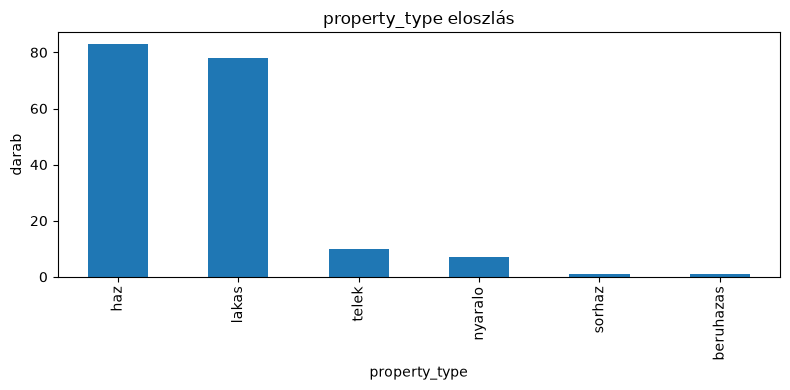

In [2]:
# B) Osztályozáshoz: property_type eloszlás -> van-e elég minta minden osztályhoz?
type_counts = df["property_type"].value_counts()
print(type_counts)

type_counts.plot(kind="bar", title="property_type eloszlás")
plt.ylabel("darab")
plt.tight_layout()
plt.show()


In [3]:
# Hiányzó értékek áttekintése - oszloponként, és kulcs oszlopok property_type / portal szerint
missing_overview = df.isna().mean().sort_values(ascending=False) * 100
print("Hiányzó érték arány (%) oszloponként:")
print(missing_overview.round(1))

print("\nHiányzó 'rooms' arány (%) property_type szerint (C) és B) relevancia):")
print((df.groupby("property_type")["rooms"].apply(lambda s: s.isna().mean() * 100)).round(1))

print("\nHiányzó 'lat' arány (%) portal szerint (C) klaszterezés relevancia):")
print((df.groupby("portal")["lat"].apply(lambda s: s.isna().mean() * 100)).round(1))


Hiányzó érték arány (%) oszloponként:
rooms            40.0
lat              21.1
lon              21.1
title            11.7
portal            0.0
url               0.0
price             0.0
property_type     0.0
property_id       0.0
currency          0.0
location          0.0
area_sqm          0.0
parsed_at         0.0
source_file       0.0
dtype: float64

Hiányzó 'rooms' arány (%) property_type szerint (C) és B) relevancia):
property_type
beruhazas    100.0
haz           26.5
lakas         46.2
nyaralo       42.9
sorhaz         0.0
telek        100.0
Name: rooms, dtype: float64

Hiányzó 'lat' arány (%) portal szerint (C) klaszterezés relevancia):
portal
dh.hu               25.0
ingatlanbazar.hu     0.0
jofogas.hu          88.2
oc.hu               11.3
zenga.hu             0.0
Name: lat, dtype: float64


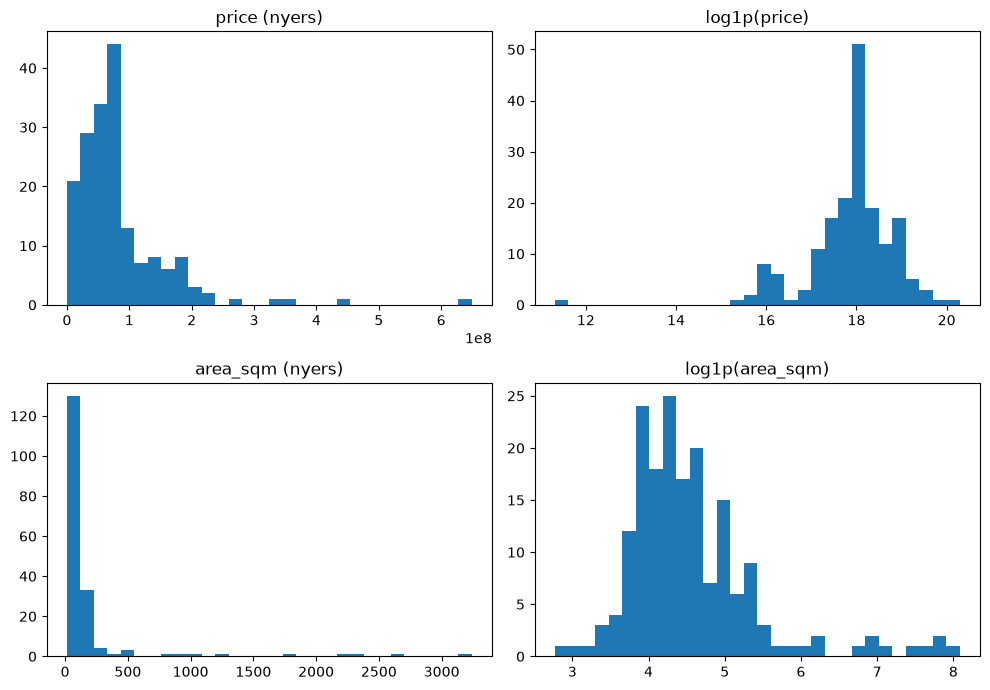

price leíró statisztika:
count    1.800000e+02
mean     8.414003e+07
std      7.770485e+07
min      8.200000e+04
25%      4.187500e+07
50%      6.720000e+07
75%      9.679290e+07
max      6.490000e+08
Name: price, dtype: float64

area_sqm leíró statisztika:
count     180.000000
mean      185.872222
std       425.272637
min        15.000000
25%        54.000000
50%        80.000000
75%       135.000000
max      3240.000000
Name: area_sqm, dtype: float64


In [4]:
# A) Regresszióhoz: price és area_sqm eloszlása -> erős jobbra elnyúlás, log-transzformáció indokolt?
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].hist(df["price"], bins=30)
axes[0, 0].set_title("price (nyers)")

axes[0, 1].hist(np.log1p(df["price"]), bins=30)
axes[0, 1].set_title("log1p(price)")

axes[1, 0].hist(df["area_sqm"], bins=30)
axes[1, 0].set_title("area_sqm (nyers)")

axes[1, 1].hist(np.log1p(df["area_sqm"]), bins=30)
axes[1, 1].set_title("log1p(area_sqm)")

plt.tight_layout()
plt.show()

print("price leíró statisztika:")
print(df["price"].describe())
print("\narea_sqm leíró statisztika:")
print(df["area_sqm"].describe())


Koordinátával rendelkező sorok: 142 / 180 (78.9%)


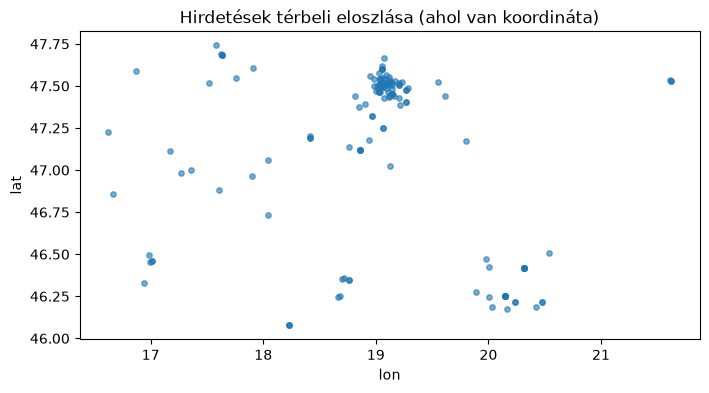

In [5]:
# C) Klaszterezéshez: mennyi sor rendelkezik érvényes lat/lon-nal?
has_coords = df["lat"].notna() & df["lon"].notna()
print(f"Koordinátával rendelkező sorok: {has_coords.sum()} / {len(df)} ({has_coords.mean()*100:.1f}%)")

plt.scatter(df.loc[has_coords, "lon"], df.loc[has_coords, "lat"], s=15, alpha=0.6)
plt.xlabel("lon")
plt.ylabel("lat")
plt.title("Hirdetések térbeli eloszlása (ahol van koordináta)")
plt.show()


### Következtetés (3. pont)

- **A) Regresszió marad a fő irány**: `price`/`area_sqm` minden sorra megvan, a log-transzformáció láthatóan segít a torzított eloszláson.
- **B) Osztályozás** csak kiegészítő lehet: a `sorhaz` és `beruhazas` osztályok 1 elemesek, ezek nélkül (haz/lakas/telek/nyaralo) még belefér 4 osztály.
- **C) Klaszterezés** jelenleg korlátozott a hiányzó koordináták miatt (lásd portálonkénti arány fent) — érdemes csak a koordinátával rendelkező részhalmazon futtatni, és megjegyzést tenni a lefedettség korlátairól.
- **D) Anomália detektálás** csak az A) modell felépítése után értelmezhető (reziduum alapú), ezért ezt később, a modellezési notebookban érdemes megcsinálni.

## 4. Előfeldolgozási terv megvalósítása

Az alábbi lépések a `plan.md` 4. pontját követik: hiányzó értékek kezelése, `location` feldolgozás, transzformációk, kódolás. A cél egy `df_prep` DataFrame, ami már közvetlenül modellezhető.


### 4.1 Alapok: oszlopok szűkítése, konstans oszlop elhagyása

In [6]:
assert df["currency"].nunique() == 1, "currency nem konstans, ezt a lépést felül kell vizsgálni"

df_prep = df.drop(columns=["currency"]).copy()
print("currency eldobva (mindig HUF, nem hordoz infót)")
df_prep.shape


currency eldobva (mindig HUF, nem hordoz infót)


(180, 13)

### 4.2 Hiányzó `rooms` kezelése

- `telek`-nél a hiány logikus (földterületnek nincs szobaszáma) → `0`.
- a többi típusnál mediánnal pótoljuk, **típuson belül** (egy háznak és egy lakásnak más a tipikus szobaszáma).
- megtartjuk egy `rooms_missing` flag-et, mert az imputálás önmagában információt veszít — a modell hasznosíthatja, hogy eredetileg hiányzott-e.

In [7]:
df_prep["rooms_missing"] = df_prep["rooms"].isna().astype(int)

df_prep.loc[df_prep["property_type"] == "telek", "rooms"] = df_prep.loc[
    df_prep["property_type"] == "telek", "rooms"
].fillna(0)

median_by_type = df_prep.groupby("property_type")["rooms"].median()
print("Medián szobaszám típusonként (imputáláshoz):")
print(median_by_type)

df_prep["rooms"] = df_prep["rooms"].fillna(df_prep["property_type"].map(median_by_type))

# fallback: ha egy típusnak nincs semennyi ismert rooms értéke (pl. 1 elemű ritka osztály,
# aminek épp az az 1 sora hiányos), az átlagos mediánnal pótoljuk
overall_median = df_prep["rooms"].median()
df_prep["rooms"] = df_prep["rooms"].fillna(overall_median)

print("\nHiányzó rooms az imputálás után:", df_prep["rooms"].isna().sum())


Medián szobaszám típusonként (imputáláshoz):
property_type
beruhazas    NaN
haz          3.0
lakas        2.0
nyaralo      3.0
sorhaz       2.0
telek        0.0
Name: rooms, dtype: float64

Hiányzó rooms az imputálás után: 0


### 4.3 `location` feldolgozás

A `location` szabad szöveg (134 egyedi érték / 180 sor), direkt kategóriaként kezelhetetlen. Két hasznos jellemzőt nyerünk ki belőle:

- **`is_budapest`**: a hirdetés Budapesten van-e (ez önmagában erős ár-jelzés).
- **`settlement`**: az első vessző előtti rész, ami jellemzően a település (vagy "Budapest" + kerület) — ezt később csoportosítjuk, mert 134 egyedi érték túl sok lenne one-hot kódolásnak.

In [8]:
def extract_settlement(location: str, portal: str):
    """Település kinyerése a szabad szöveges location mezőből.

    A location formátuma portálonként eltér:
    - a legtöbb portálnál (dh.hu, oc.hu, ingatlanbazar.hu, zenga.hu) a település
      az első vessző előtti rész (irányítószámot levágva), pl.
      "9444 Fertőszentmiklós , -" vagy "Köveskál, Köveskál";
    - a jofogas.hu viszont "<kategória>[, <alkategória>], <megye>, <település>"
      formátumot használ (pl. "Telek, föld, Győr-Moson-Sopron, Töltéstava"),
      itt a település az **utolsó** vessző utáni rész.
    Budapestet mindkét esetben külön kezeljük, mert a kerület-infó miatt
    a vessző-pozíció nem egységes nála sem.
    """
    if pd.isna(location):
        return None
    text = location.strip()
    if re.search(r"budapest", text, flags=re.IGNORECASE):
        return "Budapest"
    parts = [p.strip() for p in text.split(",") if p.strip()]
    if not parts:
        return None
    if portal == "jofogas.hu":
        return parts[-1]
    first = re.sub(r"^\d{4}\s*", "", parts[0])  # vezető irányítószám levágása
    return first or None


df_prep["settlement"] = [
    extract_settlement(loc, portal) for loc, portal in zip(df_prep["location"], df_prep["portal"])
]
df_prep["is_budapest"] = (df_prep["settlement"] == "Budapest").astype(int)

print("Kinyert település hiányzik:", df_prep["settlement"].isna().sum(), "sorban")
print("\nTop 15 település:")
print(df_prep["settlement"].value_counts().head(15))
print("\nBudapesti hirdetések aránya:", f"{df_prep['is_budapest'].mean()*100:.1f}%")


Kinyert település hiányzik: 0 sorban

Top 15 település:
settlement
Budapest            65
Debrecen             9
Hódmezővásárhely     6
Szeged               6
Győr                 5
Adony                4
Szekszárd            4
Nagykanizsa          4
Nyalka               3
Pécs                 3
Székesfehérvár       3
Dunaújváros          2
Kemecse              2
Tököl                2
Vecsés               2
Name: count, dtype: int64

Budapesti hirdetések aránya: 36.1%


In [9]:
ROMAN_NUMERALS = r"I|II|III|IV|V|VI|VII|VIII|IX|X|XI|XII|XIII|XIV|XV|XVI|XVII|XVIII|XIX|XX|XXI|XXII|XXIII"


def extract_district(location: str):
    """Budapesti kerület kinyerése szövegként, pl. 'XIV.' vagy '12.' formából."""
    if pd.isna(location) or "budapest" not in location.lower():
        return None
    roman = re.search(rf"\b({ROMAN_NUMERALS})\.\s*kerület", location, flags=re.IGNORECASE)
    if roman:
        return roman.group(1).upper()
    arabic = re.search(r"\b(\d{1,2})\.\s*kerület", location, flags=re.IGNORECASE)
    if arabic:
        return arabic.group(1)
    return None


df_prep["bp_district"] = df_prep["location"].apply(extract_district)
print("Felismert budapesti kerületek (ahol van):")
print(df_prep.loc[df_prep["is_budapest"] == 1, "bp_district"].value_counts(dropna=False))

# Nem-budapesti települések túl sok egyedi értéke miatt: top N megtartása, a ritkák "egyeb" kategóriába
TOP_N_SETTLEMENT = 10
top_settlements = df_prep.loc[df_prep["is_budapest"] == 0, "settlement"].value_counts().head(TOP_N_SETTLEMENT).index
df_prep["settlement_grouped"] = np.where(
    df_prep["is_budapest"] == 1,
    "Budapest",
    np.where(df_prep["settlement"].isin(top_settlements), df_prep["settlement"], "egyeb"),
)
print("\nsettlement_grouped eloszlás:")
print(df_prep["settlement_grouped"].value_counts())


Felismert budapesti kerületek (ahol van):
bp_district
XIV      8
III      7
VII      6
XI       5
XVI      5
XIX      5
II       4
XIII     4
V        3
XVII     3
XX       3
XV       2
VIII     2
XVIII    2
12       1
IX       1
XXI      1
IV       1
X        1
XII      1
Name: count, dtype: int64

settlement_grouped eloszlás:
settlement_grouped
egyeb               68
Budapest            65
Debrecen             9
Hódmezővásárhely     6
Szeged               6
Győr                 5
Adony                4
Szekszárd            4
Nagykanizsa          4
Nyalka               3
Pécs                 3
Székesfehérvár       3
Name: count, dtype: int64


### 4.4 Hiányzó `lat`/`lon` és Budapest-távolság feature

A koordináta sok sornál hiányzik (főleg jofogas.hu), ezért nem imputáljuk mesterségesen (a found hibás koordináta rosszabb lenne, mint a hiány jelzése). Helyette:

- megtartjuk a `has_coords` flaget,
- a meglévő koordinátákból kiszámoljuk a **Budapest centrumtól mért légvonalbeli távolságot** (km), ami numerikus proxy lehet a település típusára/elhelyezkedésére ott, ahol van koordináta.

In [10]:
BUDAPEST_LAT, BUDAPEST_LON = 47.4979, 19.0402


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


df_prep["has_coords"] = (df_prep["lat"].notna() & df_prep["lon"].notna()).astype(int)
df_prep["dist_to_bp_km"] = np.where(
    df_prep["has_coords"] == 1,
    haversine_km(df_prep["lat"], df_prep["lon"], BUDAPEST_LAT, BUDAPEST_LON),
    np.nan,
)

print(df_prep[["has_coords", "dist_to_bp_km"]].describe())


       has_coords  dist_to_bp_km
count  180.000000     142.000000
mean     0.788889      72.284997
std      0.409235      71.170131
min      0.000000       1.223823
25%      1.000000       8.391936
50%      1.000000      37.498153
75%      1.000000     149.725137
max      1.000000     205.740127


### 4.5 Transzformációk és kiugró értékek

- `log_price`, `log_area_sqm`: log1p-transzformáció a jobbra elnyúló eloszlás miatt (lásd 3. pont hisztogramok).
- `price_per_sqm` és `log_price_per_sqm`: alternatív célváltozó, amely kiszűri a terület hatását.
- Kiugró értékek **jelzése** (nem automatikus eldobása) az 1. és 99. percentilis alapján — a döntést a modellezési notebookban hozzuk meg, itt csak feltárjuk.

In [11]:
df_prep["log_price"] = np.log1p(df_prep["price"])
df_prep["log_area_sqm"] = np.log1p(df_prep["area_sqm"])
df_prep["price_per_sqm"] = df_prep["price"] / df_prep["area_sqm"]
df_prep["log_price_per_sqm"] = np.log1p(df_prep["price_per_sqm"])


def flag_outliers(series, lower_q=0.01, upper_q=0.99):
    lo, hi = series.quantile([lower_q, upper_q])
    return (series < lo) | (series > hi)


df_prep["price_outlier"] = flag_outliers(df_prep["price"]).astype(int)
df_prep["area_outlier"] = flag_outliers(df_prep["area_sqm"]).astype(int)
df_prep["price_per_sqm_outlier"] = flag_outliers(df_prep["price_per_sqm"]).astype(int)

print("Kiugrónak jelölt sorok (price):", df_prep["price_outlier"].sum())
print("Kiugrónak jelölt sorok (area_sqm):", df_prep["area_outlier"].sum())
print("Kiugrónak jelölt sorok (price_per_sqm):", df_prep["price_per_sqm_outlier"].sum())

df_prep.loc[
    (df_prep["price_outlier"] == 1) | (df_prep["area_outlier"] == 1) | (df_prep["price_per_sqm_outlier"] == 1),
    ["property_type", "price", "area_sqm", "price_per_sqm", "settlement"],
].sort_values("price_per_sqm")


Kiugrónak jelölt sorok (price): 4
Kiugrónak jelölt sorok (area_sqm): 4
Kiugrónak jelölt sorok (price_per_sqm): 4


,property_type,price,area_sqm,price_per_sqm,settlement
87,haz,82000,141,5.815603e+02,Székesfehérvár
13,telek,9500000,3240,2.932099e+03,Gyömöre
16,telek,10000000,2702,3.700962e+03,Kajárpéc
156,haz,4900000,15,3.266667e+05,Szekszárd
165,nyaralo,8200000,20,4.100000e+05,Sümeg
138,beruhazas,449000000,380,1.181579e+06,Budapest
170,haz,649000000,469,1.383795e+06,Balatonfüred
3,lakas,189800000,86,2.206977e+06,Budapest
166,haz,324900000,146,2.225342e+06,Budapest


### 4.6 Kategorikus kódolás

- `property_type`: one-hot kódolás (alacsony kardinalitás, 4-6 osztály).
- `settlement_grouped`: one-hot kódolás (top-N település + "egyeb" + "Budapest", lásd 4.3).
- `portal`: megtartjuk informatív oszlopként, de **nem** kódoljuk be a modellbe alapból — ez adatforrás-zajt kódolna, a modellezési notebookban külön döntés kell, hogy bekerüljön-e.

In [12]:
df_prep = pd.get_dummies(
    df_prep,
    columns=["property_type", "settlement_grouped"],
    prefix=["type", "settl"],
)

print("Oszlopok a kódolás után:")
print(list(df_prep.columns))
df_prep.shape


Oszlopok a kódolás után:
['url', 'portal', 'property_id', 'title', 'price', 'area_sqm', 'rooms', 'location', 'lat', 'lon', 'parsed_at', 'source_file', 'rooms_missing', 'settlement', 'is_budapest', 'bp_district', 'has_coords', 'dist_to_bp_km', 'log_price', 'log_area_sqm', 'price_per_sqm', 'log_price_per_sqm', 'price_outlier', 'area_outlier', 'price_per_sqm_outlier', 'type_beruhazas', 'type_haz', 'type_lakas', 'type_nyaralo', 'type_sorhaz', 'type_telek', 'settl_Adony', 'settl_Budapest', 'settl_Debrecen', 'settl_Győr', 'settl_Hódmezővásárhely', 'settl_Nagykanizsa', 'settl_Nyalka', 'settl_Pécs', 'settl_Szeged', 'settl_Szekszárd', 'settl_Székesfehérvár', 'settl_egyeb']


(180, 43)

### 4.7 Végső ellenőrzés és mentés

Ellenőrizzük, hogy a modellezéshez tervezett numerikus oszlopokban nincs maradék hiányzó érték (a `lat`/`lon`/`dist_to_bp_km` szándékosan hiányos marad ott, ahol nincs koordináta), majd elmentjük az eredményt, hogy a modellezési notebook ebből induljon tovább.

In [13]:
cols_must_be_complete = ["rooms", "rooms_missing", "log_price", "log_area_sqm", "is_budapest", "has_coords"]
missing_after = df_prep[cols_must_be_complete].isna().sum()
assert missing_after.sum() == 0, f"Váratlan hiányzó érték maradt:\n{missing_after}"
print("OK: a kulcs-oszlopokban nincs hiányzó érték.")

print("\nSzándékosan hiányos oszlopok (koordináta-függők):")
print(df_prep[["lat", "lon", "dist_to_bp_km"]].isna().sum())

out_path = "../data/properties_preprocessed.csv"
df_prep.to_csv(out_path, index=False)
print(f"\nElőfeldolgozott adat elmentve: {out_path} ({df_prep.shape[0]} sor, {df_prep.shape[1]} oszlop)")


OK: a kulcs-oszlopokban nincs hiányzó érték.

Szándékosan hiányos oszlopok (koordináta-függők):
lat              38
lon              38
dist_to_bp_km    38
dtype: int64

Előfeldolgozott adat elmentve: ../data/properties_preprocessed.csv (180 sor, 43 oszlop)


## Összefoglalás és következő lépés

- A 3. pont alapján a **regresszió** (ár / ár-m² becslés) a fő irány, osztályozás és klaszterezés kiegészítő lehet, anomália-detektálás a modellezés után jön szóba.
- A 4. pont preprocessing lépései elkészültek: `rooms` imputálás + flag, `location` → `settlement`/`is_budapest`/`bp_district`, koordináta-alapú `dist_to_bp_km` + `has_coords`, log-transzformációk, kiugró érték jelzés, one-hot kódolás.
- Eredmény: `../data/properties_preprocessed.csv`, ez a modellezési notebook (plan.md 5. pont: modellek és kísérleti terv) bemeneti adata lesz.
- **Ne feledd**: ezt a notebookot érdemes újrafuttatni, amint bővül a `properties.csv` — a cellák erre úgy készültek, hogy robusztusak legyenek a sorszám növekedésére (típusonkénti/portálonkénti arányokkal dolgoznak, nem fix indexekkel).